# Practical 8: Graph-Based Recommender System Using GNN

## Aim

To model MovieLens Small as a **bipartite user-movie interaction graph**, implement a **LightGCN-style graph neural recommender**, generate Top-N recommendations, evaluate ranking performance, and analyze user-item interaction patterns.

The graph contains:

- user nodes
- movie nodes
- positive user-movie interaction edges

The propagation rule is:

\[
E^{(l+1)} = D^{-1/2} A D^{-1/2} E^{(l)}
\]

The model is trained with Bayesian Personalized Ranking (BPR) so that a user's observed positive movie receives a higher score than an unobserved negative movie.


## 1. Mount Google Drive


In [1]:
# 1. Mount Google Drive
# ------------------------------------------------------------

from google.colab import drive
drive.mount("/content/drive")


# ------------------------------------------------------------


Mounted at /content/drive


## 2. Import libraries


In [2]:
# 2. Import libraries
# ------------------------------------------------------------

import os
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

import torch
import torch.nn as nn
import torch.nn.functional as F


# ------------------------------------------------------------


## 3. Settings


In [ ]:
# 3. Settings
# ------------------------------------------------------------

DATA_FOLDER = "/content/drive/MyDrive/RS/ML_Small"

RATINGS_FILE = os.path.join(
    DATA_FOLDER,
    "ratings.csv"
)

MOVIES_FILE = os.path.join(
    DATA_FOLDER,
    "movies.csv"
)

POSITIVE_THRESHOLD = 4.0

EMBEDDING_DIM = 64
NUM_LAYERS = 2

LEARNING_RATE = 0.01
WEIGHT_DECAY = 1e-4

BATCH_SIZE = 2048
EPOCHS = 30

TOP_N = 10
RANKING_K = 10

DEMO_USER_ID = 25

RANDOM_STATE = 42

DEVICE = (
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)


# ------------------------------------------------------------


## 4. Reproducibility


In [4]:
# 4. Reproducibility
# ------------------------------------------------------------

random.seed(
    RANDOM_STATE
)

np.random.seed(
    RANDOM_STATE
)

torch.manual_seed(
    RANDOM_STATE
)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(
        RANDOM_STATE
    )


# ------------------------------------------------------------


## 5. Load MovieLens Small


In [5]:
# 5. Load MovieLens Small
# ------------------------------------------------------------

ratings = pd.read_csv(
    RATINGS_FILE
)

movies = pd.read_csv(
    MOVIES_FILE
)

required_rating_columns = {
    "userId",
    "movieId",
    "rating",
    "timestamp"
}

required_movie_columns = {
    "movieId",
    "title",
    "genres"
}

if not required_rating_columns.issubset(
    ratings.columns
):
    raise ValueError(
        "ratings.csv must contain "
        "userId, movieId, rating and timestamp."
    )

if not required_movie_columns.issubset(
    movies.columns
):
    raise ValueError(
        "movies.csv must contain "
        "movieId, title and genres."
    )

print("=" * 70)
print("MOVIELENS SMALL")
print("=" * 70)

print("Ratings shape:", ratings.shape)
print("Movies shape :", movies.shape)

print(
    "Users:",
    ratings["userId"].nunique()
)

print(
    "Rated movies:",
    ratings["movieId"].nunique()
)

print(
    "Ratings:",
    len(ratings)
)

print(
    "Device:",
    DEVICE
)

display(
    ratings.head()
)

display(
    movies.head()
)


# ------------------------------------------------------------


MOVIELENS SMALL
Ratings shape: (100836, 4)
Movies shape : (9742, 3)
Users: 610
Rated movies: 9724
Ratings: 100836
Device: cpu


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


## 6. Convert explicit ratings to positive graph interactions


In [6]:
# 6. Convert explicit ratings to positive graph interactions
#
# For this graph recommender, an edge means that the user
# positively interacted with the movie.
#
# rating >= POSITIVE_THRESHOLD -> positive edge
# ------------------------------------------------------------

positive = ratings[
    ratings["rating"]
    >= POSITIVE_THRESHOLD
].copy()

positive = (
    positive
    .sort_values(
        [
            "userId",
            "timestamp"
        ]
    )
    .reset_index(
        drop=True
    )
)

print("\n" + "=" * 70)
print("POSITIVE INTERACTION GRAPH")
print("=" * 70)

print(
    "Positive interactions:",
    len(positive)
)

print(
    "Users with positive interactions:",
    positive["userId"].nunique()
)

print(
    "Movies with positive interactions:",
    positive["movieId"].nunique()
)


# ------------------------------------------------------------



POSITIVE INTERACTION GRAPH
Positive interactions: 48580
Users with positive interactions: 609
Movies with positive interactions: 6298


## 7. Keep users with at least 3 positive interactions


In [7]:
# 7. Keep users with at least 3 positive interactions
#
# We need:
# earlier positives -> training graph
# second-last       -> validation positive
# last              -> test positive
# ------------------------------------------------------------

user_positive_counts = (
    positive["userId"]
    .value_counts()
)

eligible_users = (
    user_positive_counts[
        user_positive_counts >= 3
    ]
    .index
)

positive = positive[
    positive["userId"].isin(
        eligible_users
    )
].copy()

print(
    "\nEligible users:",
    positive["userId"].nunique()
)


# ------------------------------------------------------------



Eligible users: 608


## 8. Temporal train / validation / test split


In [8]:
# 8. Temporal train / validation / test split
# ------------------------------------------------------------

train_rows = []
validation_rows = []
test_rows = []

for user_id, group in positive.groupby(
    "userId",
    sort=False
):

    group = group.sort_values(
        "timestamp"
    )

    train_rows.append(
        group.iloc[:-2]
    )

    validation_rows.append(
        group.iloc[[-2]]
    )

    test_rows.append(
        group.iloc[[-1]]
    )

train_data = pd.concat(
    train_rows,
    ignore_index=True
)

validation_data = pd.concat(
    validation_rows,
    ignore_index=True
)

test_data = pd.concat(
    test_rows,
    ignore_index=True
)

print("\nTraining positive edges:", len(train_data))
print("Validation edges       :", len(validation_data))
print("Test edges             :", len(test_data))


# ------------------------------------------------------------



Training positive edges: 47363
Validation edges       : 608
Test edges             : 608


## 9. Build compact user and movie ID mappings


In [9]:
# 9. Build compact user and movie ID mappings
# ------------------------------------------------------------

user_ids = np.sort(
    positive["userId"].unique()
)

movie_ids = np.sort(
    positive["movieId"].unique()
)

user_to_index = {
    user_id: index
    for index, user_id
    in enumerate(user_ids)
}

index_to_user = {
    index: user_id
    for user_id, index
    in user_to_index.items()
}

movie_to_index = {
    movie_id: index
    for index, movie_id
    in enumerate(movie_ids)
}

index_to_movie = {
    index: movie_id
    for movie_id, index
    in movie_to_index.items()
}

NUM_USERS = len(
    user_ids
)

NUM_MOVIES = len(
    movie_ids
)

NUM_NODES = (
    NUM_USERS
    + NUM_MOVIES
)

print("\nNumber of user nodes :", NUM_USERS)
print("Number of movie nodes:", NUM_MOVIES)
print("Total graph nodes    :", NUM_NODES)


# ------------------------------------------------------------



Number of user nodes : 608
Number of movie nodes: 6298
Total graph nodes    : 6906


## 10. Movie title lookup


In [10]:
# 10. Movie title lookup
# ------------------------------------------------------------

movie_titles = (
    movies
    .drop_duplicates(
        "movieId"
    )
    .set_index(
        "movieId"
    )["title"]
)


# ------------------------------------------------------------


## 11. Analyse user-item interaction patterns


In [11]:
# 11. Analyse user-item interaction patterns
# ------------------------------------------------------------

train_user_degree = (
    train_data["userId"]
    .value_counts()
    .reindex(
        user_ids,
        fill_value=0
    )
)

train_movie_degree = (
    train_data["movieId"]
    .value_counts()
    .reindex(
        movie_ids,
        fill_value=0
    )
)

graph_density = (
    len(train_data)
    /
    (
        NUM_USERS
        * NUM_MOVIES
    )
)

print("\n" + "=" * 70)
print("GRAPH INTERACTION PATTERNS")
print("=" * 70)

print(
    f"Graph density: "
    f"{graph_density:.6f}"
)

print(
    f"Graph sparsity: "
    f"{1.0 - graph_density:.6f}"
)

print(
    "Average positive interactions per user:",
    round(
        train_user_degree.mean(),
        2
    )
)

print(
    "Average positive interactions per movie:",
    round(
        train_movie_degree.mean(),
        2
    )
)

print("\nMost active users")
display(
    train_user_degree
    .sort_values(
        ascending=False
    )
    .head(10)
    .rename(
        "Training Positive Degree"
    )
    .reset_index()
    .rename(
        columns={
            "index": "userId"
        }
    )
)

top_movies = (
    train_movie_degree
    .sort_values(
        ascending=False
    )
    .head(10)
    .rename(
        "Training Positive Degree"
    )
    .reset_index()
    .rename(
        columns={
            "index": "movieId"
        }
    )
)

top_movies[
    "Movie"
] = top_movies[
    "movieId"
].map(
    movie_titles
)

print("\nMost connected movies")
display(
    top_movies[
        [
            "movieId",
            "Movie",
            "Training Positive Degree"
        ]
    ]
)


# ------------------------------------------------------------



GRAPH INTERACTION PATTERNS
Graph density: 0.012369
Graph sparsity: 0.987631
Average positive interactions per user: 77.9
Average positive interactions per movie: 7.52

Most active users


,userId,Training Positive Degree
0,414,1225
1,474,785
2,380,667
3,610,612
4,606,611
5,603,561
6,105,552
7,249,509
8,182,486
9,448,453



Most connected movies


,movieId,Movie,Training Positive Degree
0,318,"Shawshank Redemption, The (1994)",270
1,356,Forrest Gump (1994),244
2,296,Pulp Fiction (1994),241
3,2571,"Matrix, The (1999)",220
4,593,"Silence of the Lambs, The (1991)",220
5,260,Star Wars: Episode IV - A New Hope (1977),199
6,2959,Fight Club (1999),179
7,527,Schindler's List (1993),168
8,1196,Star Wars: Episode V - The Empire Strikes Back...,166
9,110,Braveheart (1995),163


## 12. Visualize user-degree distribution


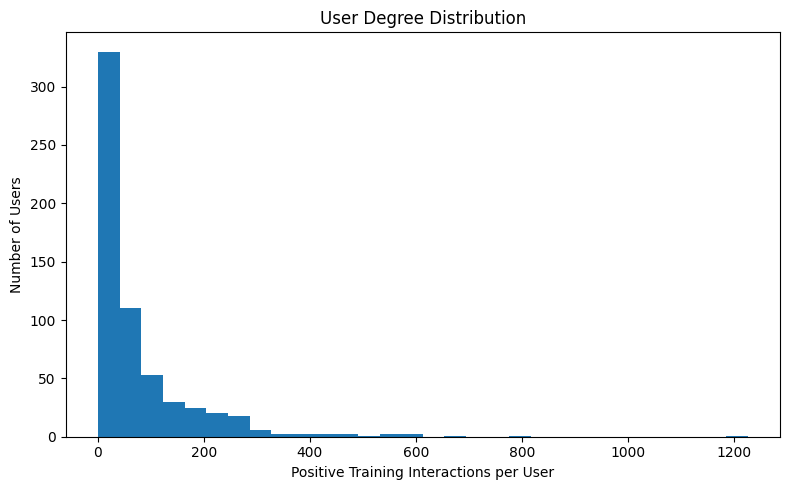

In [12]:
# 12. Visualize user-degree distribution
# ------------------------------------------------------------

plt.figure(
    figsize=(8, 5)
)

plt.hist(
    train_user_degree.values,
    bins=30
)

plt.xlabel(
    "Positive Training Interactions per User"
)

plt.ylabel(
    "Number of Users"
)

plt.title(
    "User Degree Distribution"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------


## 13. Visualize movie-degree distribution


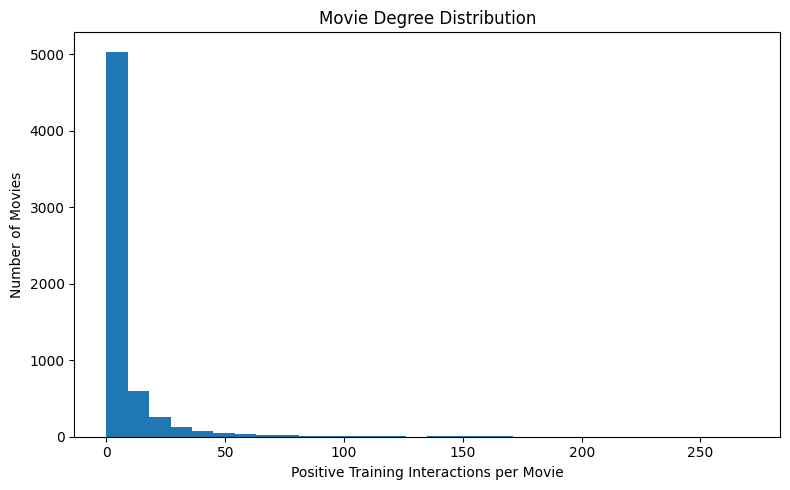

In [13]:
# 13. Visualize movie-degree distribution
# ------------------------------------------------------------

plt.figure(
    figsize=(8, 5)
)

plt.hist(
    train_movie_degree.values,
    bins=30
)

plt.xlabel(
    "Positive Training Interactions per Movie"
)

plt.ylabel(
    "Number of Movies"
)

plt.title(
    "Movie Degree Distribution"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------


## 14. Visualize a small bipartite interaction subgraph


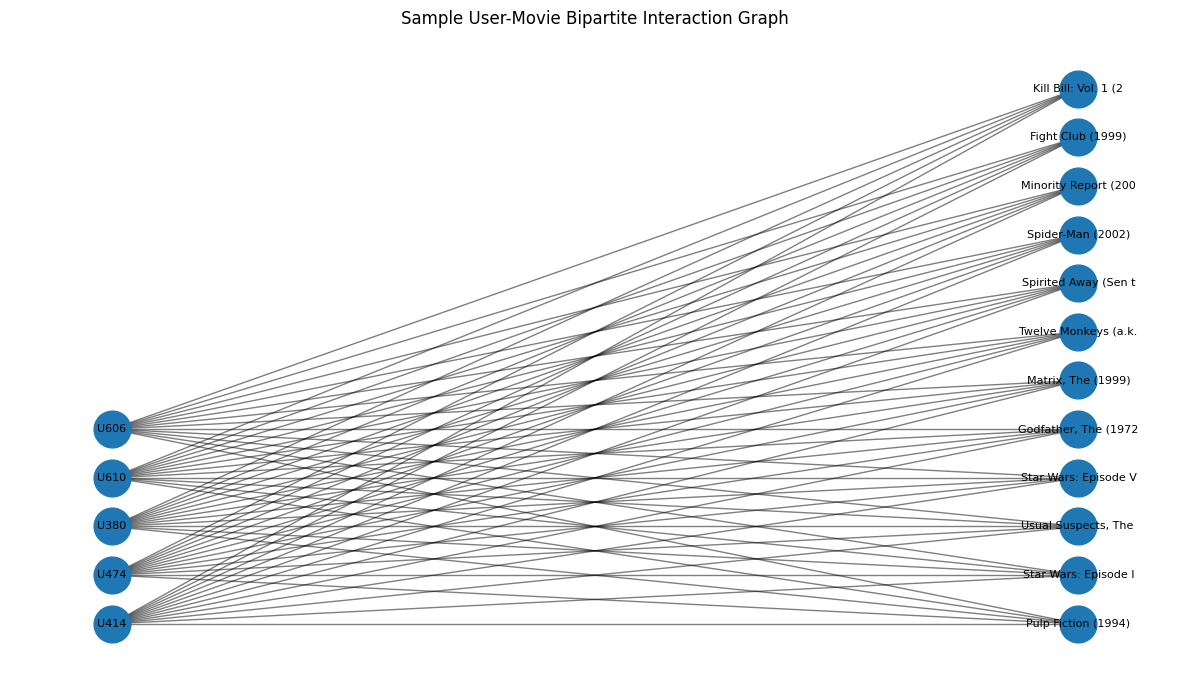

In [14]:
# 14. Visualize a small bipartite interaction subgraph
#
# Use the most active users and their connected training movies.
# ------------------------------------------------------------

top_user_ids = (
    train_user_degree
    .sort_values(
        ascending=False
    )
    .head(5)
    .index
    .tolist()
)

sub_edges = train_data[
    train_data["userId"].isin(
        top_user_ids
    )
].copy()

# Keep only the most frequently connected movies in this subset
# so that the graph remains readable.
sub_movie_counts = (
    sub_edges["movieId"]
    .value_counts()
    .head(12)
)

sub_movie_ids = (
    sub_movie_counts
    .index
    .tolist()
)

sub_edges = sub_edges[
    sub_edges["movieId"].isin(
        sub_movie_ids
    )
]

G = nx.Graph()

for user_id in top_user_ids:
    G.add_node(
        f"U{user_id}",
        bipartite=0
    )

for movie_id in sub_movie_ids:

    title = (
        movie_titles.loc[
            movie_id
        ]
        if movie_id
        in movie_titles.index
        else str(
            movie_id
        )
    )

    G.add_node(
        f"M{movie_id}",
        bipartite=1,
        label=title
    )

for row in sub_edges.itertuples():

    G.add_edge(
        f"U{row.userId}",
        f"M{row.movieId}"
    )

if len(G.nodes) > 0:

    user_nodes = [
        node
        for node, data
        in G.nodes(
            data=True
        )
        if data[
            "bipartite"
        ] == 0
    ]

    movie_nodes = [
        node
        for node, data
        in G.nodes(
            data=True
        )
        if data[
            "bipartite"
        ] == 1
    ]

    positions = {}

    for index, node in enumerate(
        user_nodes
    ):

        positions[
            node
        ] = (
            0,
            index
        )

    for index, node in enumerate(
        movie_nodes
    ):

        positions[
            node
        ] = (
            1,
            index
        )

    plt.figure(
        figsize=(12, 7)
    )

    nx.draw_networkx_nodes(
        G,
        positions,
        nodelist=user_nodes,
        node_size=700
    )

    nx.draw_networkx_nodes(
        G,
        positions,
        nodelist=movie_nodes,
        node_size=700
    )

    nx.draw_networkx_edges(
        G,
        positions,
        alpha=0.5
    )

    labels = {}

    for node in user_nodes:
        labels[
            node
        ] = node

    for node in movie_nodes:

        movie_id = int(
            node[1:]
        )

        title = (
            movie_titles.loc[
                movie_id
            ]
            if movie_id
            in movie_titles.index
            else str(
                movie_id
            )
        )

        labels[
            node
        ] = title[:20]

    nx.draw_networkx_labels(
        G,
        positions,
        labels=labels,
        font_size=8
    )

    plt.title(
        "Sample User-Movie Bipartite Interaction Graph"
    )

    plt.axis(
        "off"
    )

    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------


## 15. Create training-edge index arrays


In [15]:
# 15. Create training-edge index arrays
# ------------------------------------------------------------

train_user_indices = np.array(
    [
        user_to_index[
            user_id
        ]
        for user_id
        in train_data[
            "userId"
        ]
    ],
    dtype=np.int64
)

train_movie_indices = np.array(
    [
        movie_to_index[
            movie_id
        ]
        for movie_id
        in train_data[
            "movieId"
        ]
    ],
    dtype=np.int64
)


# ------------------------------------------------------------


## 16. Build training-positive sets for negative sampling


In [16]:
# 16. Build training-positive sets for negative sampling
# ------------------------------------------------------------

train_positive_sets = {
    user_index: set()
    for user_index
    in range(
        NUM_USERS
    )
}

for user_index, movie_index in zip(
    train_user_indices,
    train_movie_indices
):

    train_positive_sets[
        user_index
    ].add(
        movie_index
    )


# ------------------------------------------------------------


## 17. Build normalized bipartite adjacency matrix


In [17]:
# 17. Build normalized bipartite adjacency matrix
#
# Node indexing:
#
# user nodes:
# 0 ... NUM_USERS-1
#
# movie nodes:
# NUM_USERS ... NUM_USERS+NUM_MOVIES-1
#
# Each user-movie edge is made bidirectional.
#
# LightGCN propagation:
#
# E^(l+1) = D^(-1/2) A D^(-1/2) E^(l)
# ------------------------------------------------------------

def build_normalized_adjacency(
    user_indices,
    movie_indices,
    num_users,
    num_movies,
    device
):
    """
    Construct a symmetric normalized sparse adjacency matrix.

    Parameters
    ----------
    user_indices:
        Integer user indices for all training edges.

    movie_indices:
        Integer movie indices for all training edges.

    num_users:
        Number of user nodes.

    num_movies:
        Number of movie nodes.

    device:
        CPU or CUDA device.

    Returns
    -------
    normalized_adj:
        Sparse PyTorch matrix with shape
        (num_users + num_movies, num_users + num_movies).
    """

    movie_nodes = (
        movie_indices
        + num_users
    )

    row = np.concatenate(
        [
            user_indices,
            movie_nodes
        ]
    )

    col = np.concatenate(
        [
            movie_nodes,
            user_indices
        ]
    )

    values = np.ones(
        len(
            row
        ),
        dtype=np.float32
    )

    degree = np.bincount(
        row,
        minlength=(
            num_users
            + num_movies
        )
    ).astype(
        np.float32
    )

    degree_inv_sqrt = np.zeros_like(
        degree
    )

    nonzero = degree > 0

    degree_inv_sqrt[
        nonzero
    ] = (
        1.0
        / np.sqrt(
            degree[
                nonzero
            ]
        )
    )

    normalized_values = (
        values
        * degree_inv_sqrt[
            row
        ]
        * degree_inv_sqrt[
            col
        ]
    )

    indices = torch.tensor(
        np.vstack(
            [
                row,
                col
            ]
        ),
        dtype=torch.long
    )

    values_tensor = torch.tensor(
        normalized_values,
        dtype=torch.float32
    )

    normalized_adj = torch.sparse_coo_tensor(
        indices,
        values_tensor,
        size=(
            num_users
            + num_movies,
            num_users
            + num_movies
        )
    )

    normalized_adj = (
        normalized_adj
        .coalesce()
        .to(
            device
        )
    )

    return normalized_adj


normalized_adj = build_normalized_adjacency(
    train_user_indices,
    train_movie_indices,
    NUM_USERS,
    NUM_MOVIES,
    DEVICE
)

print(
    "\nNormalized adjacency shape:",
    normalized_adj.shape
)

print(
    "Number of directed sparse entries:",
    normalized_adj._nnz()
)


# ------------------------------------------------------------



Normalized adjacency shape: torch.Size([6906, 6906])
Number of directed sparse entries: 94726


/tmp/ipykernel_1295/971458825.py:130: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:760.)
  normalized_adj = torch.sparse_coo_tensor(


## 18. LightGCN model


In [18]:
# 18. LightGCN model
#
# LightGCN removes feature transforms and nonlinearities.
# It keeps the graph-neighborhood aggregation that matters for
# collaborative recommendation.
# ------------------------------------------------------------

class LightGCN(nn.Module):

    def __init__(
        self,
        num_users,
        num_movies,
        embedding_dim=64,
        num_layers=2
    ):
        """
        Parameters
        ----------
        num_users:
            Number of user nodes.

        num_movies:
            Number of movie nodes.

        embedding_dim:
            Size of every trainable node embedding.

        num_layers:
            Number of graph propagation steps.
        """

        super().__init__()

        self.num_users = (
            num_users
        )

        self.num_movies = (
            num_movies
        )

        self.embedding_dim = (
            embedding_dim
        )

        self.num_layers = (
            num_layers
        )

        self.user_embedding = nn.Embedding(
            num_users,
            embedding_dim
        )

        self.movie_embedding = nn.Embedding(
            num_movies,
            embedding_dim
        )

        nn.init.normal_(
            self.user_embedding.weight,
            std=0.1
        )

        nn.init.normal_(
            self.movie_embedding.weight,
            std=0.1
        )


    def propagate(
        self,
        normalized_adj
    ):
        """
        Perform LightGCN neighborhood aggregation.

        Initial embeddings are layer 0.

        Each new layer is obtained by multiplying the normalized
        adjacency matrix by the previous node embeddings.

        The final representation is the mean of embeddings from
        layer 0 through layer L.
        """

        all_embeddings = torch.cat(
            [
                self.user_embedding.weight,
                self.movie_embedding.weight
            ],
            dim=0
        )

        layer_embeddings = [
            all_embeddings
        ]

        current = (
            all_embeddings
        )

        for layer in range(
            self.num_layers
        ):

            current = torch.sparse.mm(
                normalized_adj,
                current
            )

            layer_embeddings.append(
                current
            )

        final_embeddings = torch.mean(
            torch.stack(
                layer_embeddings,
                dim=0
            ),
            dim=0
        )

        final_user_embeddings = (
            final_embeddings[
                :self.num_users
            ]
        )

        final_movie_embeddings = (
            final_embeddings[
                self.num_users:
            ]
        )

        return (
            final_user_embeddings,
            final_movie_embeddings
        )


    def score(
        self,
        user_indices,
        movie_indices,
        normalized_adj
    ):
        """
        Dot-product preference score for user-movie pairs.
        """

        (
            user_embeddings,
            movie_embeddings
        ) = self.propagate(
            normalized_adj
        )

        selected_users = (
            user_embeddings[
                user_indices
            ]
        )

        selected_movies = (
            movie_embeddings[
                movie_indices
            ]
        )

        scores = torch.sum(
            selected_users
            * selected_movies,
            dim=1
        )

        return scores


# ------------------------------------------------------------


## 19. Instantiate model and optimizer


In [19]:
# 19. Instantiate model and optimizer
# ------------------------------------------------------------

model = LightGCN(
    num_users=NUM_USERS,
    num_movies=NUM_MOVIES,
    embedding_dim=EMBEDDING_DIM,
    num_layers=NUM_LAYERS
).to(
    DEVICE
)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

print("\n" + "=" * 70)
print("LIGHTGCN MODEL")
print("=" * 70)

print(model)


# ------------------------------------------------------------



LIGHTGCN MODEL
LightGCN(
  (user_embedding): Embedding(608, 64)
  (movie_embedding): Embedding(6298, 64)
)


## 20. Negative sampling


In [20]:
# 20. Negative sampling
#
# For each positive (user, movie) edge, sample one movie that
# the user did not positively interact with in the training graph.
# ------------------------------------------------------------

def sample_negative_movies(
    user_batch,
    positive_sets,
    num_movies
):
    """
    Sample one negative movie for each user in user_batch.

    user_batch:
        NumPy array of user indices.

    positive_sets:
        Dictionary user_index -> set of positive training movies.

    num_movies:
        Total number of movie nodes.
    """

    negatives = np.empty(
        len(
            user_batch
        ),
        dtype=np.int64
    )

    for position, user_index in enumerate(
        user_batch
    ):

        negative = np.random.randint(
            0,
            num_movies
        )

        while negative in positive_sets[
            int(
                user_index
            )
        ]:

            negative = np.random.randint(
                0,
                num_movies
            )

        negatives[
            position
        ] = negative

    return negatives


# ------------------------------------------------------------


## 21. BPR loss


In [21]:
# 21. BPR loss
#
# We want:
#
# score(user, positive_movie)
# >
# score(user, negative_movie)
#
# Loss:
#
# -log sigmoid(pos_score - neg_score)
# ------------------------------------------------------------

def bpr_loss(
    user_embeddings,
    positive_embeddings,
    negative_embeddings
):
    """
    Bayesian Personalized Ranking loss for one batch.
    """

    positive_scores = torch.sum(
        user_embeddings
        * positive_embeddings,
        dim=1
    )

    negative_scores = torch.sum(
        user_embeddings
        * negative_embeddings,
        dim=1
    )

    loss = -torch.mean(
        F.logsigmoid(
            positive_scores
            - negative_scores
        )
    )

    return loss


# ------------------------------------------------------------


## 22. Train LightGCN


In [22]:
# 22. Train LightGCN
# ------------------------------------------------------------

train_edge_count = len(
    train_user_indices
)

training_loss_history = []

for epoch in range(
    1,
    EPOCHS + 1
):

    model.train()

    permutation = np.random.permutation(
        train_edge_count
    )

    epoch_loss = 0.0
    batch_count = 0

    for start in range(
        0,
        train_edge_count,
        BATCH_SIZE
    ):

        batch_positions = permutation[
            start:
            start + BATCH_SIZE
        ]

        user_batch_np = train_user_indices[
            batch_positions
        ]

        positive_batch_np = train_movie_indices[
            batch_positions
        ]

        negative_batch_np = sample_negative_movies(
            user_batch_np,
            train_positive_sets,
            NUM_MOVIES
        )

        user_batch = torch.tensor(
            user_batch_np,
            dtype=torch.long,
            device=DEVICE
        )

        positive_batch = torch.tensor(
            positive_batch_np,
            dtype=torch.long,
            device=DEVICE
        )

        negative_batch = torch.tensor(
            negative_batch_np,
            dtype=torch.long,
            device=DEVICE
        )

        optimizer.zero_grad()

        (
            propagated_users,
            propagated_movies
        ) = model.propagate(
            normalized_adj
        )

        user_embeddings = (
            propagated_users[
                user_batch
            ]
        )

        positive_embeddings = (
            propagated_movies[
                positive_batch
            ]
        )

        negative_embeddings = (
            propagated_movies[
                negative_batch
            ]
        )

        loss = bpr_loss(
            user_embeddings,
            positive_embeddings,
            negative_embeddings
        )

        loss.backward()

        optimizer.step()

        epoch_loss += float(
            loss.item()
        )

        batch_count += 1

    mean_epoch_loss = (
        epoch_loss
        / max(
            batch_count,
            1
        )
    )

    training_loss_history.append(
        mean_epoch_loss
    )

    print(
        f"Epoch {epoch:02d} | "
        f"BPR Loss = "
        f"{mean_epoch_loss:.6f}"
    )


# ------------------------------------------------------------


Epoch 01 | BPR Loss = 0.650822
Epoch 02 | BPR Loss = 0.397535
Epoch 03 | BPR Loss = 0.390598
Epoch 04 | BPR Loss = 0.384820
Epoch 05 | BPR Loss = 0.379039
Epoch 06 | BPR Loss = 0.374766
Epoch 07 | BPR Loss = 0.373142
Epoch 08 | BPR Loss = 0.373313
Epoch 09 | BPR Loss = 0.373728
Epoch 10 | BPR Loss = 0.368391
Epoch 11 | BPR Loss = 0.373033
Epoch 12 | BPR Loss = 0.368982
Epoch 13 | BPR Loss = 0.372748
Epoch 14 | BPR Loss = 0.368454
Epoch 15 | BPR Loss = 0.369056
Epoch 16 | BPR Loss = 0.372339
Epoch 17 | BPR Loss = 0.372359
Epoch 18 | BPR Loss = 0.370241
Epoch 19 | BPR Loss = 0.370962
Epoch 20 | BPR Loss = 0.375438
Epoch 21 | BPR Loss = 0.372335
Epoch 22 | BPR Loss = 0.370695
Epoch 23 | BPR Loss = 0.374371
Epoch 24 | BPR Loss = 0.371684
Epoch 25 | BPR Loss = 0.371354
Epoch 26 | BPR Loss = 0.372724
Epoch 27 | BPR Loss = 0.370268
Epoch 28 | BPR Loss = 0.372153
Epoch 29 | BPR Loss = 0.370594
Epoch 30 | BPR Loss = 0.371961


## 23. Plot training loss


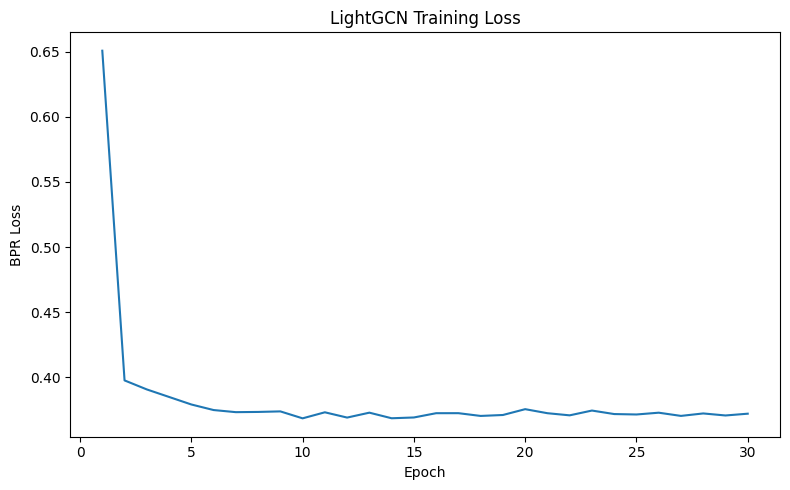

In [23]:
# 23. Plot training loss
# ------------------------------------------------------------

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    range(
        1,
        len(
            training_loss_history
        ) + 1
    ),
    training_loss_history
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "BPR Loss"
)

plt.title(
    "LightGCN Training Loss"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------


## 24. Get final propagated embeddings


In [24]:
# 24. Get final propagated embeddings
# ------------------------------------------------------------

model.eval()

with torch.no_grad():

    (
        final_user_embeddings,
        final_movie_embeddings
    ) = model.propagate(
        normalized_adj
    )


# ------------------------------------------------------------


## 25. Recommendation function


In [25]:
# 25. Recommendation function
# ------------------------------------------------------------

def recommend_movies(
    user_id,
    top_n=TOP_N
):
    """
    Rank unseen movies for one user using the dot product between
    the learned user embedding and all movie embeddings.
    """

    if user_id not in user_to_index:
        return pd.DataFrame()

    user_index = user_to_index[
        user_id
    ]

    with torch.no_grad():

        user_vector = (
            final_user_embeddings[
                user_index
            ]
        )

        scores = torch.mv(
            final_movie_embeddings,
            user_vector
        )

        scores = scores.detach().cpu().numpy()

    seen_movies = train_positive_sets[
        user_index
    ]

    if len(
        seen_movies
    ) > 0:

        seen_array = np.array(
            list(
                seen_movies
            ),
            dtype=int
        )

        scores[
            seen_array
        ] = -np.inf

    valid_indices = np.where(
        np.isfinite(
            scores
        )
    )[0]

    if len(
        valid_indices
    ) == 0:
        return pd.DataFrame()

    n_keep = min(
        top_n,
        len(
            valid_indices
        )
    )

    valid_scores = scores[
        valid_indices
    ]

    top_local = np.argpartition(
        valid_scores,
        -n_keep
    )[-n_keep:]

    top_movie_indices = (
        valid_indices[
            top_local
        ]
    )

    top_movie_indices = (
        top_movie_indices[
            np.argsort(
                scores[
                    top_movie_indices
                ]
            )[::-1]
        ]
    )

    rows = []

    for rank, movie_index in enumerate(
        top_movie_indices,
        start=1
    ):

        movie_id = index_to_movie[
            int(
                movie_index
            )
        ]

        title = (
            movie_titles.loc[
                movie_id
            ]
            if movie_id
            in movie_titles.index
            else str(
                movie_id
            )
        )

        rows.append({
            "Rank": rank,
            "movieId": movie_id,
            "Movie": title,
            "GNN Score": float(
                scores[
                    movie_index
                ]
            )
        })

    return pd.DataFrame(
        rows
    )


# ------------------------------------------------------------


## 26. Demo recommendations


In [26]:
# 26. Demo recommendations
# ------------------------------------------------------------

if DEMO_USER_ID not in user_to_index:
    DEMO_USER_ID = int(
        user_ids[
            0
        ]
    )

demo_recommendations = recommend_movies(
    DEMO_USER_ID,
    top_n=TOP_N
)

print("\n" + "=" * 70)

print(
    f"TOP {TOP_N} GNN RECOMMENDATIONS "
    f"FOR USER {DEMO_USER_ID}"
)

print("=" * 70)

display(
    demo_recommendations
)


# ------------------------------------------------------------



TOP 10 GNN RECOMMENDATIONS FOR USER 25


,Rank,movieId,Movie,GNN Score
0,1,318,"Shawshank Redemption, The (1994)",2.176380
1,2,356,Forrest Gump (1994),2.059480
2,3,296,Pulp Fiction (1994),2.021194
3,4,593,"Silence of the Lambs, The (1991)",1.860313
4,5,2959,Fight Club (1999),1.788885
5,6,1196,Star Wars: Episode V - The Empire Strikes Back...,1.636259
6,7,589,Terminator 2: Judgment Day (1991),1.622142
7,8,50,"Usual Suspects, The (1995)",1.616873
8,9,110,Braveheart (1995),1.616071
9,10,858,"Godfather, The (1972)",1.575219


## 27. Visualize Top-N recommendations


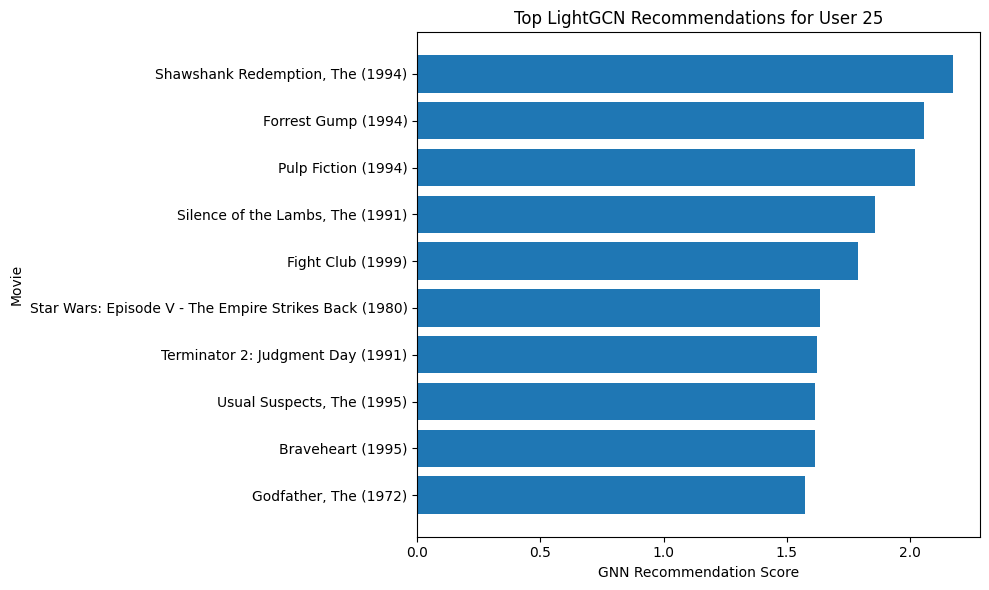

In [27]:
# 27. Visualize Top-N recommendations
# ------------------------------------------------------------

if not demo_recommendations.empty:

    plot_data = (
        demo_recommendations
        .sort_values(
            "GNN Score",
            ascending=True
        )
    )

    plt.figure(
        figsize=(10, 6)
    )

    plt.barh(
        plot_data[
            "Movie"
        ],
        plot_data[
            "GNN Score"
        ]
    )

    plt.xlabel(
        "GNN Recommendation Score"
    )

    plt.ylabel(
        "Movie"
    )

    plt.title(
        f"Top LightGCN Recommendations "
        f"for User {DEMO_USER_ID}"
    )

    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------


## 28. Ranking helper


In [ ]:
# 28. Ranking helper
# ------------------------------------------------------------

def rank_target_movie(
    user_id,
    target_movie_id
):
    """
    Return the 1-based rank of the held-out target movie.
    """

    if (
        user_id not in user_to_index
        or target_movie_id not in movie_to_index
    ):
        return None

    user_index = user_to_index[
        user_id
    ]

    target_movie_index = movie_to_index[
        target_movie_id
    ]

    with torch.no_grad():

        user_vector = (
            final_user_embeddings[
                user_index
            ]
        )

        scores = torch.mv(
            final_movie_embeddings,
            user_vector
        )

        scores = (
            scores
            .detach()
            .cpu()
            .numpy()
        )

    seen_movies = train_positive_sets[
        user_index
    ]

    if len(
        seen_movies
    ) > 0:

        seen_array = np.array(
            list(
                seen_movies
            ),
            dtype=int
        )

        scores[
            seen_array
        ] = -np.inf

    target_score = scores[
        target_movie_index
    ]

    if not np.isfinite(
        target_score
    ):
        return None

    rank = (
        int(
            np.sum(
                scores
                > target_score
            )
        )
        + 1
    )

    return rank


# ------------------------------------------------------------


## 29. Evaluate next positive item recommendation


In [ ]:
# 29. Evaluate next positive item recommendation
#
# Metrics:
# Hit Rate@10
# MRR@10
# NDCG@10
# ------------------------------------------------------------

evaluation_rows = []

for row in test_data.itertuples():

    rank = rank_target_movie(
        row.userId,
        row.movieId
    )

    hit = int(
        rank is not None
        and rank <= RANKING_K
    )

    rr = (
        1.0 / rank
        if hit
        else 0.0
    )

    ndcg = (
        1.0
        / np.log2(
            rank + 1
        )
        if hit
        else 0.0
    )

    evaluation_rows.append({
        "userId": row.userId,
        "movieId": row.movieId,
        "Rank": rank,
        f"Hit@{RANKING_K}": hit,
        f"RR@{RANKING_K}": rr,
        f"NDCG@{RANKING_K}": ndcg
    })


evaluation_results = pd.DataFrame(
    evaluation_rows
)

hit_rate = (
    evaluation_results[
        f"Hit@{RANKING_K}"
    ].mean()
)

mrr_at_k = (
    evaluation_results[
        f"RR@{RANKING_K}"
    ].mean()
)

ndcg_at_k = (
    evaluation_results[
        f"NDCG@{RANKING_K}"
    ].mean()
)

print("\n" + "=" * 70)
print("GNN RANKING EVALUATION")
print("=" * 70)

print(
    f"Hit Rate@{RANKING_K}: "
    f"{hit_rate:.4f}"
)

print(
    f"MRR@{RANKING_K}: "
    f"{mrr_at_k:.4f}"
)

print(
    f"NDCG@{RANKING_K}: "
    f"{ndcg_at_k:.4f}"
)

display(
    evaluation_results.head(15)
)


# ------------------------------------------------------------


## 30. Analyse relationship between movie degree and GNN score


In [ ]:
# 30. Analyse relationship between movie degree and GNN score
#
# For the demo user, compare movie popularity in the training
# graph with the learned recommendation score.
# ------------------------------------------------------------

demo_user_index = user_to_index[
    DEMO_USER_ID
]

with torch.no_grad():

    demo_user_vector = (
        final_user_embeddings[
            demo_user_index
        ]
    )

    demo_scores = torch.mv(
        final_movie_embeddings,
        demo_user_vector
    ).detach().cpu().numpy()

movie_pattern_table = pd.DataFrame({
    "movieId": movie_ids,
    "Training Degree": train_movie_degree.values,
    "GNN Score": demo_scores
})

movie_pattern_table[
    "Movie"
] = movie_pattern_table[
    "movieId"
].map(
    movie_titles
)

print("\nMovie interaction pattern sample")
display(
    movie_pattern_table
    .sort_values(
        "GNN Score",
        ascending=False
    )
    .head(15)
)


# ------------------------------------------------------------


## 31. Scatter plot: item degree vs GNN score


In [ ]:
# 31. Scatter plot: item degree vs GNN score
# ------------------------------------------------------------

plt.figure(
    figsize=(8, 5)
)

plt.scatter(
    movie_pattern_table[
        "Training Degree"
    ],
    movie_pattern_table[
        "GNN Score"
    ],
    alpha=0.5
)

plt.xlabel(
    "Movie Training Degree"
)

plt.ylabel(
    "GNN Score for Demo User"
)

plt.title(
    "Interaction Degree vs Learned GNN Recommendation Score"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------


## 32. Visualize learned movie embeddings in 2D using SVD


In [ ]:
# 32. Visualize learned movie embeddings in 2D using SVD
#
# This is only for visualization.
# The recommender itself uses the full embedding dimension.
# ------------------------------------------------------------

movie_embedding_matrix = (
    final_movie_embeddings
    .detach()
    .cpu()
    .numpy()
)

centered_movie_embeddings = (
    movie_embedding_matrix
    - movie_embedding_matrix.mean(
        axis=0,
        keepdims=True
    )
)

U, S, Vt = np.linalg.svd(
    centered_movie_embeddings,
    full_matrices=False
)

movie_2d = (
    U[:, :2]
    * S[:2]
)

# Label only the most connected movies to avoid clutter.
label_movie_ids = (
    train_movie_degree
    .sort_values(
        ascending=False
    )
    .head(20)
    .index
    .tolist()
)

plt.figure(
    figsize=(9, 7)
)

plt.scatter(
    movie_2d[:, 0],
    movie_2d[:, 1],
    alpha=0.35
)

for movie_id in label_movie_ids:

    movie_index = movie_to_index[
        movie_id
    ]

    title = (
        movie_titles.loc[
            movie_id
        ]
        if movie_id
        in movie_titles.index
        else str(
            movie_id
        )
    )

    plt.annotate(
        title[:20],
        (
            movie_2d[
                movie_index,
                0
            ],
            movie_2d[
                movie_index,
                1
            ]
        ),
        fontsize=7
    )

plt.xlabel(
    "Embedding Dimension 1"
)

plt.ylabel(
    "Embedding Dimension 2"
)

plt.title(
    "2D View of Learned Movie Graph Embeddings"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------


## 33. Final summary


In [ ]:
# 33. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("PRACTICAL 8 SUMMARY")
print("=" * 70)

print(
    "Model: LightGCN-style graph neural recommender"
)

print(
    "Graph type: Bipartite user-movie interaction graph"
)

print(
    "Positive interaction threshold:",
    POSITIVE_THRESHOLD
)

print(
    "Training graph users:",
    NUM_USERS
)

print(
    "Training graph movies:",
    NUM_MOVIES
)

print(
    "Training positive edges:",
    len(
        train_data
    )
)

print(
    "Embedding dimension:",
    EMBEDDING_DIM
)

print(
    "Graph propagation layers:",
    NUM_LAYERS
)

print(
    f"Graph density: "
    f"{graph_density:.6f}"
)

print(
    f"Hit Rate@{RANKING_K}: "
    f"{hit_rate:.4f}"
)

print(
    f"MRR@{RANKING_K}: "
    f"{mrr_at_k:.4f}"
)

print(
    f"NDCG@{RANKING_K}: "
    f"{ndcg_at_k:.4f}"
)

print("""
Workflow:

MovieLens positive ratings
        ↓
User-movie bipartite graph
        ↓
Analyse user/movie node degrees
        ↓
Temporal train / validation / test edges
        ↓
Trainable user and movie embeddings
        ↓
Normalized graph message passing
        ↓
LightGCN propagated embeddings
        ↓
BPR positive-vs-negative ranking loss
        ↓
User-movie dot-product scores
        ↓
Top-N recommendations
        ↓
HR@10 / MRR@10 / NDCG@10
        ↓
Analyse degree patterns and learned embeddings
""")

print(
    "Practical completed successfully."
)
